# Task 5 — Content Rating & Genre Analysis

Explore maturity ratings and genre categories, compare Movies with TV Shows, and summarize catalogue segments.

**Project:** Auspify Technologies — Data Analysis Using Python Internship  
**Dataset:** Netflix catalogue CSV supplied for this internship  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

### Import Libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### Load The Cleaned Dataset

In [2]:
df = pd.read_csv("netflix_cleaned.csv")
print("Loaded cleaned dataset:", df.shape)
display(df.head())

Loaded cleaned dataset: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 2. Rating frequency table

In [3]:
rating_counts = df["rating"].fillna("Unknown").value_counts()
display(rating_counts.to_frame("title_count"))
rating_counts.to_csv("task5_rating_counts.csv", header=["title_count"])

,title_count
rating,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220


## 3. Visualize ratings

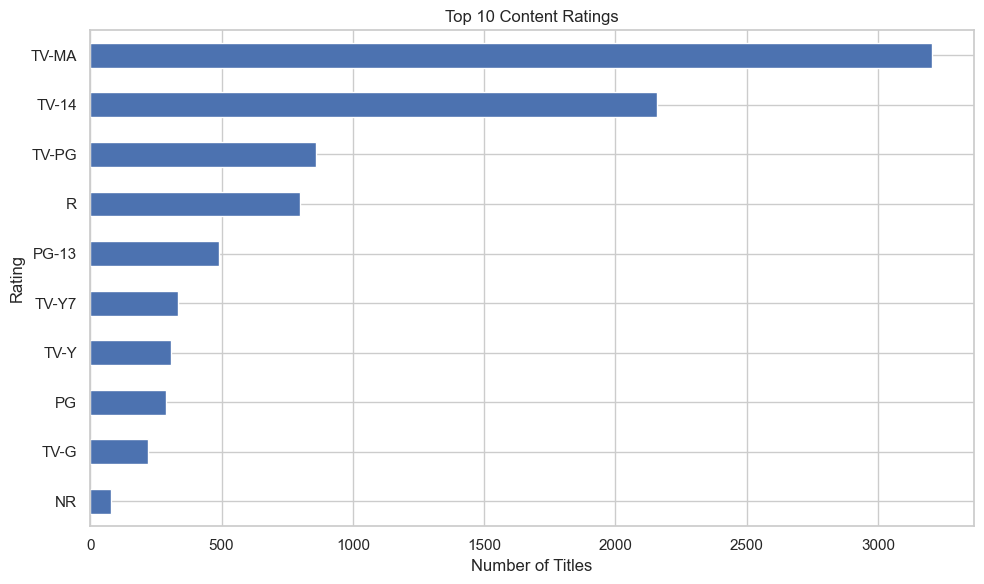

In [4]:
known_ratings = rating_counts.drop(labels=["Unknown"], errors="ignore")
rating_plot = known_ratings.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
rating_plot.plot(kind="barh", ax=ax)
ax.set(title="Top 10 Content Ratings", xlabel="Number of Titles", ylabel="Rating")
plt.tight_layout()
plt.savefig("task5_rating_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Compare ratings by content type
The normalized table compares the percentage within each type rather than raw counts.

type,Movie,Tv Show
rating,,
G,0.67,0.00
NC-17,0.05,0.00
NR,1.22,0.15
PG,4.68,0.00
PG-13,8.00,0.00
R,13.01,0.08
TV-14,23.29,27.40
TV-G,2.06,3.53
TV-MA,33.66,42.91


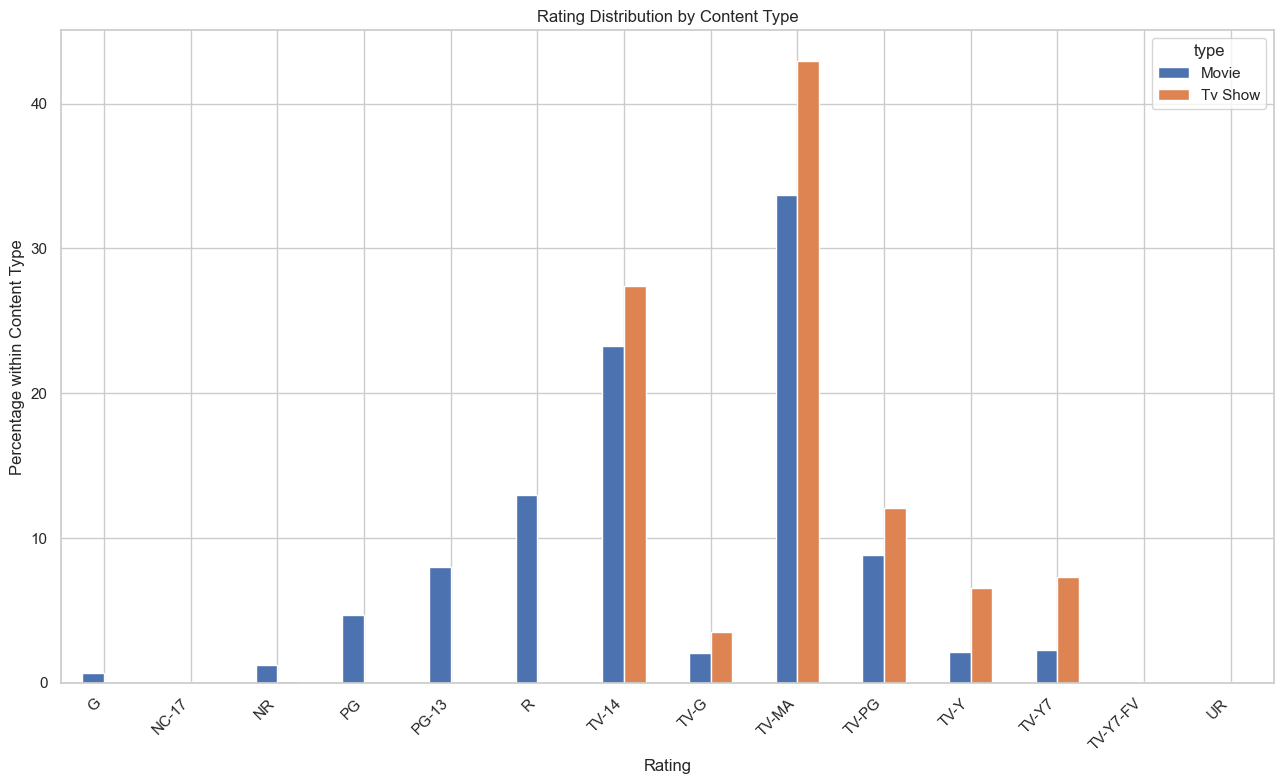

In [5]:
rating_percentages = pd.crosstab(df["rating"], df["type"], normalize="columns") * 100
rating_percentages = rating_percentages.drop(index="Unknown", errors="ignore")
display(rating_percentages.round(2))

ax = rating_percentages.plot(kind="bar", figsize=(13, 8))
ax.set(title="Rating Distribution by Content Type",
       xlabel="Rating", ylabel="Percentage within Content Type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("task5_rating_by_type.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Split genres and count title associations

In [6]:
genre_df = df[["show_id", "type", "listed_in"]].dropna(subset=["listed_in"]).copy()
genre_df["listed_in"] = genre_df["listed_in"].str.split(",")
genre_df = genre_df.explode("listed_in")
genre_df["listed_in"] = genre_df["listed_in"].str.strip()

genre_counts = (
    genre_df.groupby("listed_in")["show_id"]
    .nunique().sort_values(ascending=False)
)
display(genre_counts.head(10).to_frame("title_count"))
genre_counts.to_csv("task5_genre_counts.csv", header=["title_count"])

,title_count
listed_in,
International Movies,2752
Dramas,2426
Comedies,1674
International TV Shows,1349
Documentaries,869
Action & Adventure,859
TV Dramas,762
Independent Movies,756
Children & Family Movies,641


## 6. Visualize top genres

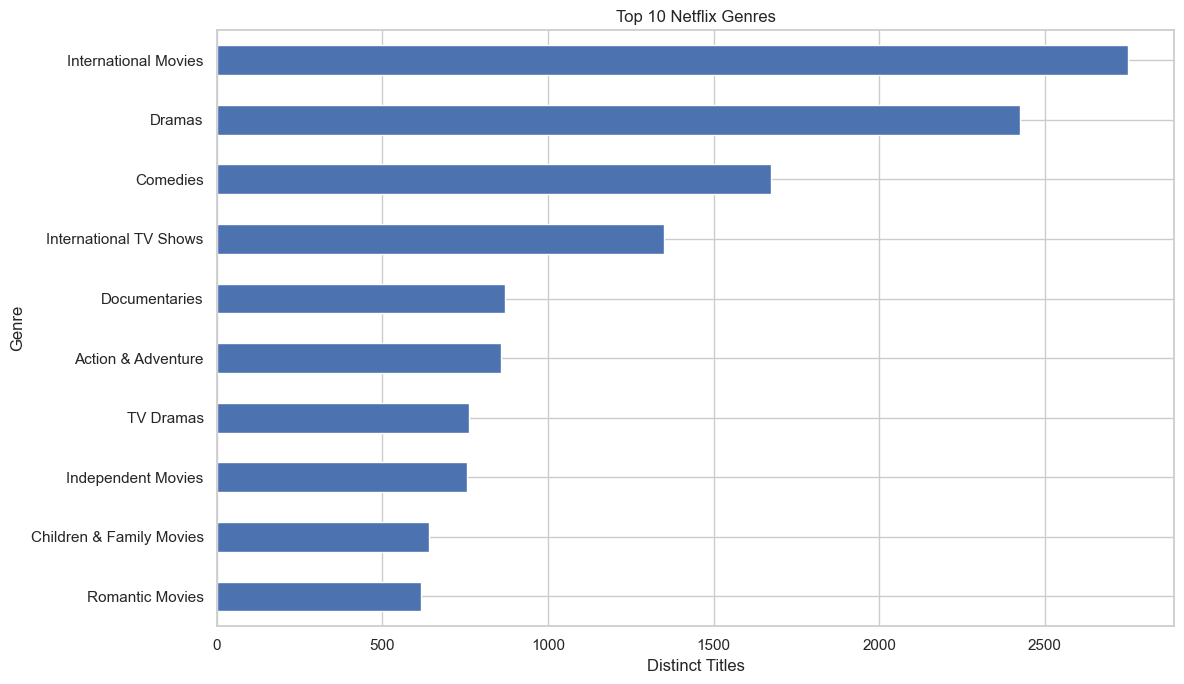

In [7]:
top_genres = genre_counts.head(10).sort_values()
fig, ax = plt.subplots(figsize=(12, 7))
top_genres.plot(kind="barh", ax=ax)
ax.set(title="Top 10 Netflix Genres", xlabel="Distinct Titles", ylabel="Genre")
plt.tight_layout()
plt.savefig("task5_top_genres.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Compare genres by type

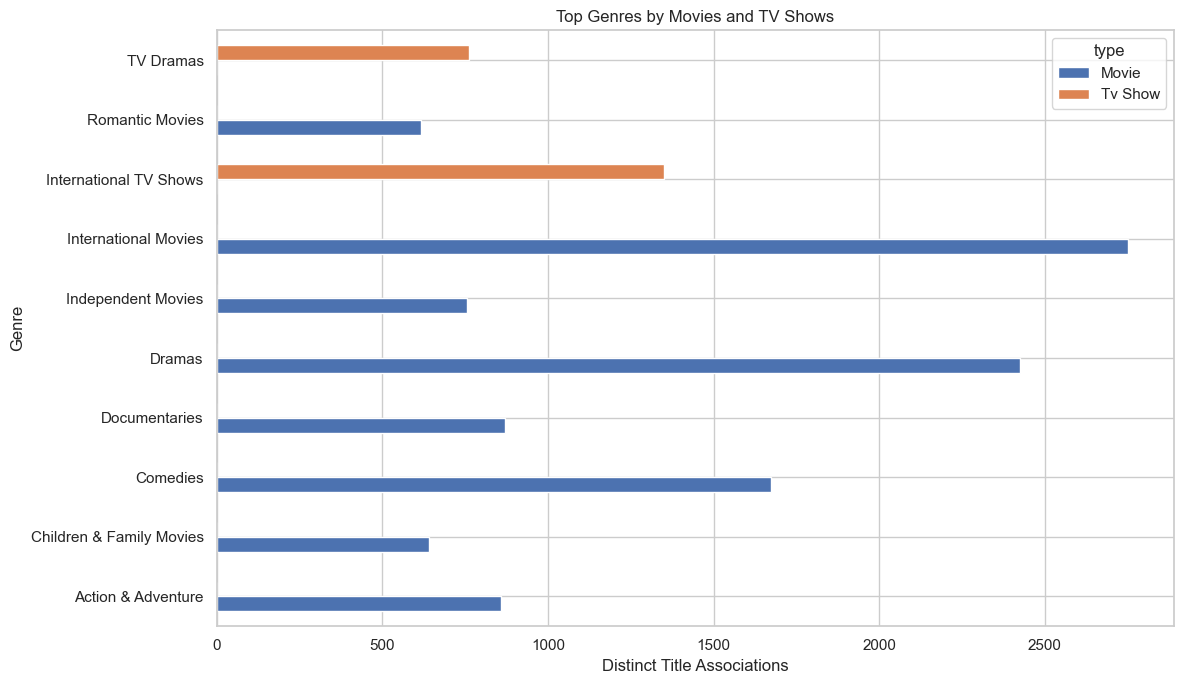

In [8]:
genre_type = (
    genre_df.groupby(["listed_in", "type"])["show_id"]
    .nunique().unstack(fill_value=0)
)
top_genre_names = genre_counts.head(10).index
genre_type_top = genre_type.loc[genre_type.index.isin(top_genre_names)]

ax = genre_type_top.plot(kind="barh", figsize=(12, 7))
ax.set(title="Top Genres by Movies and TV Shows",
       xlabel="Distinct Title Associations", ylabel="Genre")
plt.tight_layout()
plt.savefig("task5_genre_by_type.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Audience interpretation
Discuss the most frequent ratings and genres and how their distribution differs by type. Ratings and genre counts describe catalogue composition; they do not prove viewing preferences, popularity, or profitability without audience or business performance data.